In [31]:
%pip install shap lime scikit-learn pandas numpy matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [68]:
%pip install streamlit pandas numpy matplotlib seaborn plotly joblib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [32]:
# Importing all required libraries

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning explainability
import shap
from lime.lime_tabular import LimeTabularExplainer

# Model loading
import joblib
import os

# Model evaluation
from sklearn.inspection import permutation_importance

print("All explainability libraries imported successfully!")

All explainability libraries imported successfully!


In [33]:
# Load the dataset

df = pd.read_csv(
    "data/charging_records_featured.csv"
)

print("Dataset loaded successfully")

print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully
Dataset shape: (72826, 20)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculatedDuration,Hour,DayOfWeek,Month,Year,IsWeekend,TimeOfDay
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0,20,3,9,2022,0,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0,20,2,9,2022,0,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0,18,2,9,2022,0,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,00:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0,18,3,9,2022,0,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,00:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0,19,6,9,2022,1,Evening


In [34]:
# Preparing the input features


features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

print("Selected features:")

print(features)

Selected features:
['ChargerCompany', 'Location', 'ChargerType', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend']


In [35]:
# Preparing the training and testing datasets

model_df = df[
    features + ["StartDatetime", "Demand"]
].copy()

model_df["StartDatetime"] = pd.to_datetime(
    model_df["StartDatetime"],
    errors="coerce"
)

model_df = (
    model_df
    .dropna(
        subset=features + ["StartDatetime", "Demand"]
    )
    .sort_values("StartDatetime")
    .reset_index(drop=True)
)

# Chronological 80:20 split
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()

test_df = model_df.iloc[split_index:].copy()

X_train = train_df[features]

X_test = test_df[features]

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

Training records: 58260
Testing records: 14566


In [36]:
# Creating the classification target using the same training threshold.


demand_threshold = train_df["Demand"].median()

y_train = (
    train_df["Demand"] >= demand_threshold
).astype(int)

y_test = (
    test_df["Demand"] >= demand_threshold
).astype(int)

print("Demand threshold:", demand_threshold)

print("Training and testing data prepared successfully!")

Demand threshold: 14.2
Training and testing data prepared successfully!


In [37]:
# Loading your best classification model


results_df = pd.read_csv(
    "models/classification_model_comparison.csv"
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,LightGBM,0.643073,0.616022,0.711349,0.660263,0.624331
1,XGBoost,0.635109,0.609888,0.698254,0.651086,0.624331
2,SVM,0.616847,0.590915,0.696001,0.639167,0.624331
3,Logistic Regression,0.616985,0.591450,0.693467,0.638408,0.624331
4,KNN,0.596114,0.581648,0.611377,0.596142,0.624331
5,Random Forest,0.588562,0.573221,0.611236,0.591618,0.624331
6,Decision Tree,0.575656,0.570488,0.524782,0.546681,0.624331


In [38]:
# Selecting the model with the highest F1 Score.


best_model_name = (
    results_df
    .sort_values(
        by="F1 Score",
        ascending=False
    )
    .iloc[0]["Model"]
)

print("Best Classification Model:", best_model_name)

Best Classification Model: LightGBM


In [39]:
# Now loading the corresponding saved pipeline.

model_filename = (
    best_model_name.lower().replace(" ", "_")
    + "_pipeline.joblib"
)

model_path = os.path.join(
    "models",
    model_filename
)

best_model = joblib.load(model_path)

print("Best model loaded successfully!")

Best model loaded successfully!


In [40]:
# Calculating Feature Importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

feature_importance_df = pd.DataFrame({

    "Feature": features,

    "Importance": importance.importances_mean,

    "Standard Deviation": importance.importances_std

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance_df)

,Feature,Importance,Standard Deviation
0,ChargerType,0.110857,0.002798
1,Hour,0.076494,0.003629
2,ChargerCompany,0.052215,0.002002
3,Location,0.021686,0.002050
4,DayOfWeek,0.000518,0.000774
5,IsWeekend,0.000000,0.000000
6,Month,-0.000558,0.001113


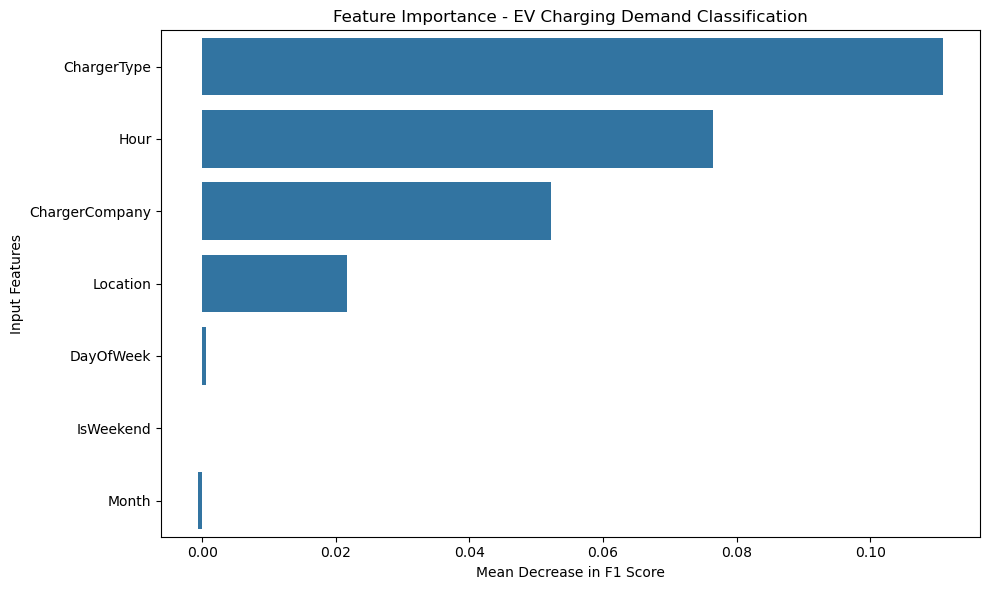

In [41]:
# Visualising Feature Importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance - EV Charging Demand Classification"
)

plt.xlabel("Mean Decrease in F1 Score")

plt.ylabel("Input Features")

plt.tight_layout()

plt.show()

In [42]:
# Extract the preprocessor and classification mode

# Extract preprocessing and trained classifier

preprocessor = best_model.named_steps["preprocessor"]

classifier = best_model.named_steps["model"]

print("Preprocessor loaded successfully!")

print("Selected classification model:", classifier)

Preprocessor loaded successfully!
Selected classification model: LGBMClassifier(n_jobs=-1, random_state=42, verbosity=-1)


In [43]:
# Convert the background and explanation data into numerical format

# Select background records
background = X_train.sample(
    n=min(20, len(X_train)),
    random_state=42
)

# Select test records to explain
explain_data = X_test.sample(
    n=min(10, len(X_test)),
    random_state=42
)

# Apply the already-fitted preprocessing pipeline
background_transformed = preprocessor.transform(
    background
)

explain_transformed = preprocessor.transform(
    explain_data
)

# Convert sparse matrix into numerical array
if hasattr(background_transformed, "toarray"):
    background_transformed = background_transformed.toarray()

if hasattr(explain_transformed, "toarray"):
    explain_transformed = explain_transformed.toarray()

print("Background data shape:", background_transformed.shape)

print("Explanation data shape:", explain_transformed.shape)

print("Data converted into numerical format successfully!")

Background data shape: (20, 22)
Explanation data shape: (10, 22)
Data converted into numerical format successfully!


In [44]:
# Get the transformed feature names

feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFeature names:")

print(feature_names)

Total transformed features: 22

Feature names:
['categorical__ChargerCompany_0' 'categorical__ChargerCompany_1'
 'categorical__Location_accommodation' 'categorical__Location_apartment'
 'categorical__Location_bus garage' 'categorical__Location_camping'
 'categorical__Location_company' 'categorical__Location_golf'
 'categorical__Location_hotel' 'categorical__Location_market'
 'categorical__Location_public area'
 'categorical__Location_public institution'
 'categorical__Location_public parking lot' 'categorical__Location_resort'
 'categorical__Location_restaurant' 'categorical__Location_sightseeing'
 'categorical__ChargerType_0' 'categorical__ChargerType_1'
 'numerical__Hour' 'numerical__DayOfWeek' 'numerical__Month'
 'numerical__IsWeekend']


In [45]:
# Create a numerical SHAP prediction function
def shap_prediction(data):

    data = np.asarray(data)

    if hasattr(classifier, "predict_proba"):

        return classifier.predict_proba(data)[:, 1]

    else:

        return classifier.decision_function(data)


print("SHAP prediction function created successfully!")

SHAP prediction function created successfully!


In [46]:
# Create the SHAP Explainer

shap_explainer = shap.Explainer(
    shap_prediction,
    background_transformed,
    algorithm="permutation",
    feature_names=feature_names
)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [47]:
# Calculate SHAP values

shap_values = shap_explainer(
    explain_transformed,
    max_evals=2 * len(feature_names) + 1
)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


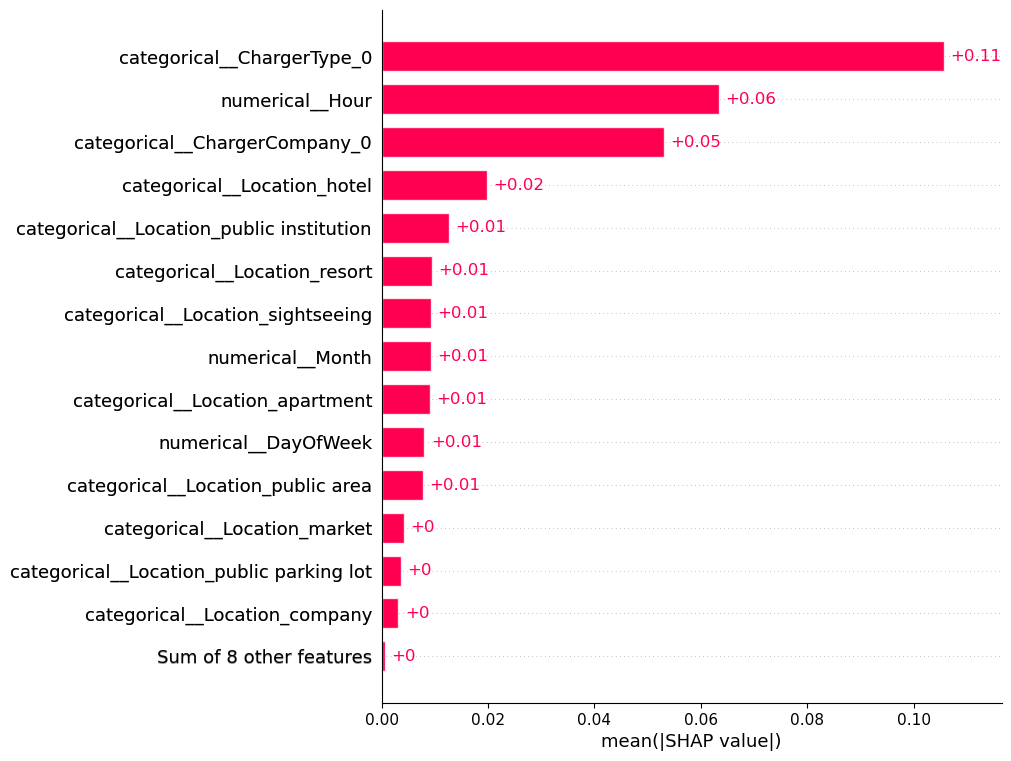

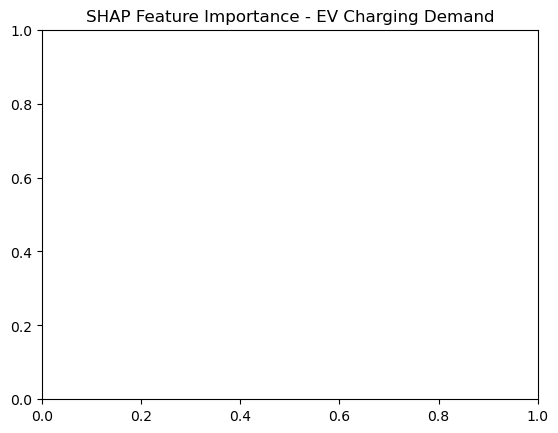

In [48]:
# Generate the SHAP Feature Importance chart

shap.plots.bar(
    shap_values,
    max_display=15
)

plt.title("SHAP Feature Importance - EV Charging Demand")

plt.show()

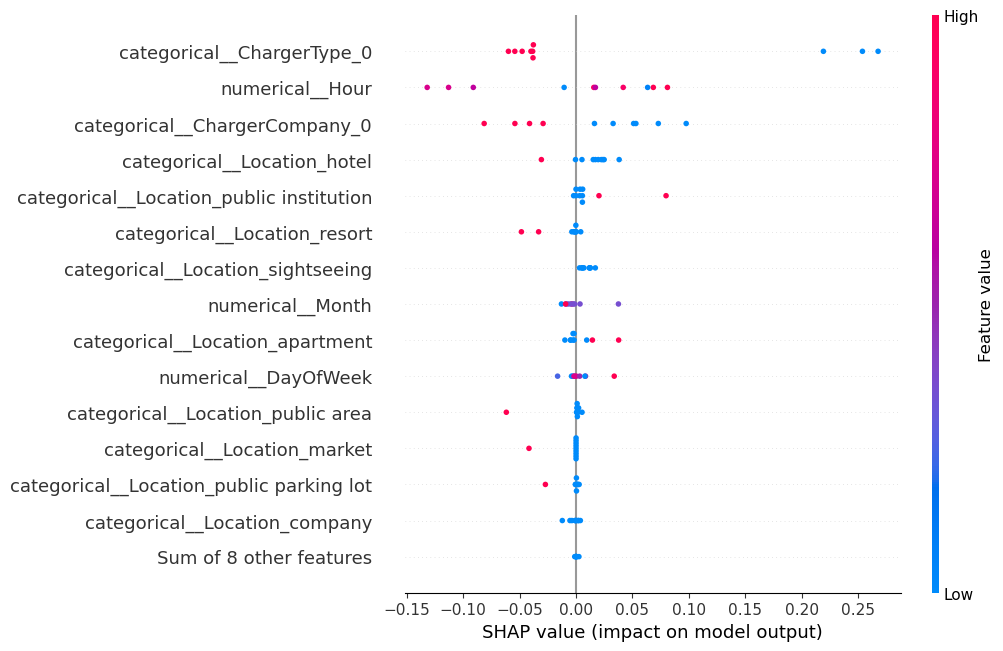

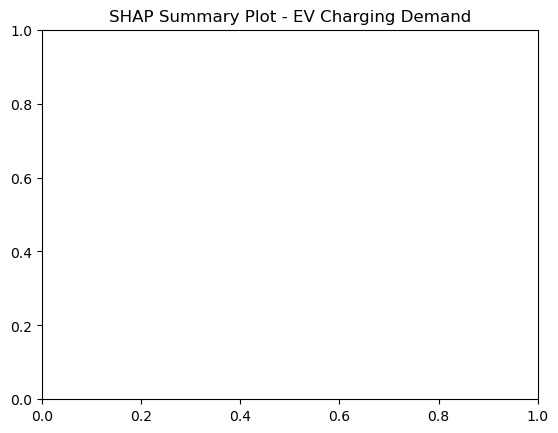

In [49]:
# Generate the SHAP Summary Plot


shap.plots.beeswarm(
    shap_values,
    max_display=15
)

plt.title("SHAP Summary Plot - EV Charging Demand")

plt.show()

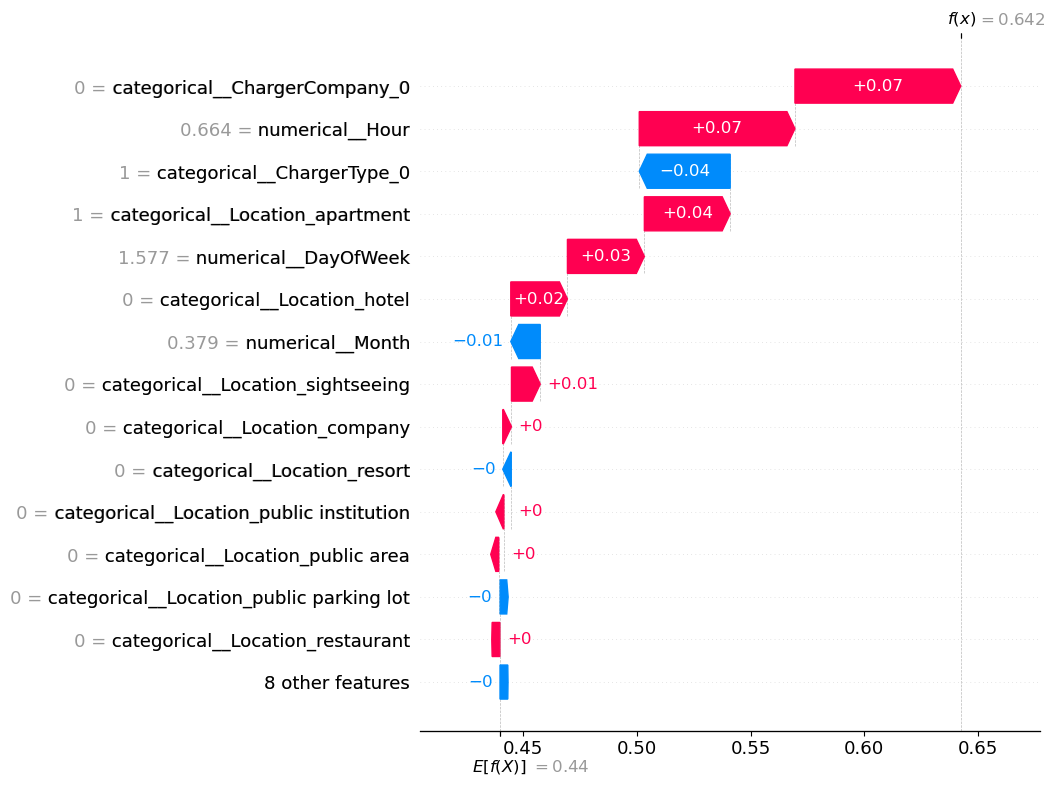

In [50]:
# Explain one individual prediction

sample_index = 0

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=15
)

In [52]:
# LIME Analysis

# Import LIME

from lime.lime_tabular import LimeTabularExplainer

print("LIME imported successfully!")

LIME imported successfully!


In [53]:
# Get the preprocessor and trained algorithm

preprocessor = best_model.named_steps["preprocessor"]

classifier = best_model.named_steps["model"]

print("Preprocessor loaded successfully!")

print("Classification algorithm:", classifier)

Preprocessor loaded successfully!
Classification algorithm: LGBMClassifier(n_jobs=-1, random_state=42, verbosity=-1)


In [54]:
# Transform the training dataset

lime_train_sample = X_train.sample(
    n=min(1000, len(X_train)),
    random_state=42
)

X_train_transformed = preprocessor.transform(
    lime_train_sample
)

X_test_transformed = preprocessor.transform(
    X_test.iloc[[0]]
)

# Convert sparse matrices to dense arrays if required
if hasattr(X_train_transformed, "toarray"):

    X_train_transformed = X_train_transformed.toarray()

if hasattr(X_test_transformed, "toarray"):

    X_test_transformed = X_test_transformed.toarray()

print("Training data transformed:", X_train_transformed.shape)

print("Test data transformed:", X_test_transformed.shape)

Training data transformed: (1000, 22)
Test data transformed: (1, 22)


In [55]:
# Get the transformed feature names

feature_names = (
    preprocessor.get_feature_names_out()
)

print("Total transformed features:", len(feature_names))

print(feature_names)

Total transformed features: 22
['categorical__ChargerCompany_0' 'categorical__ChargerCompany_1'
 'categorical__Location_accommodation' 'categorical__Location_apartment'
 'categorical__Location_bus garage' 'categorical__Location_camping'
 'categorical__Location_company' 'categorical__Location_golf'
 'categorical__Location_hotel' 'categorical__Location_market'
 'categorical__Location_public area'
 'categorical__Location_public institution'
 'categorical__Location_public parking lot' 'categorical__Location_resort'
 'categorical__Location_restaurant' 'categorical__Location_sightseeing'
 'categorical__ChargerType_0' 'categorical__ChargerType_1'
 'numerical__Hour' 'numerical__DayOfWeek' 'numerical__Month'
 'numerical__IsWeekend']


In [57]:
# Create the LIME prediction function

from scipy.special import expit

def lime_prediction(data):

    if hasattr(classifier, "predict_proba"):

        return classifier.predict_proba(data)

    else:

        decision_scores = classifier.decision_function(data)

        high_demand_score = expit(decision_scores)

        normal_demand_score = 1 - high_demand_score

        return np.column_stack([
            normal_demand_score,
            high_demand_score
        ])

In [58]:
# Create the LIME explainer

lime_explainer = LimeTabularExplainer(

    training_data=X_train_transformed,

    feature_names=feature_names,

    class_names=[
        "Normal Demand",
        "High Demand"
    ],

    mode="classification",

    discretize_continuous=True,

    random_state=42

)

print("LIME explainer created successfully!")

LIME explainer created successfully!


In [59]:
# Explain one charging session

sample_record = X_test_transformed[0]

lime_explanation = lime_explainer.explain_instance(

    data_row=sample_record,

    predict_fn=lime_prediction,

    num_features=min(10, len(feature_names)),

    labels=[1]

)

print("LIME explanation generated successfully!")

LIME explanation generated successfully!


In [64]:
# Get LIME explanation as a list

lime_results = lime_explanation.as_list(label=1)


# Convert in to Dataframe

lime_df = pd.DataFrame(
    lime_results,
    columns=["Features","Contribution"]
)

# Display results

display(lime_df)

print("\nLIME explantion generated successfully")

,Features,Contribution
0,categorical__ChargerCompany_0 <= 0.00,0.186437
1,categorical__Location_market <= 0.00,0.149437
2,categorical__Location_sightseeing <= 0.00,0.082297
3,categorical__Location_camping <= 0.00,-0.076814
4,categorical__Location_accommodation <= 0.00,-0.075837
5,0.27 < numerical__Hour <= 0.86,0.059401
6,categorical__Location_hotel <= 0.00,0.056374
7,categorical__Location_public area <= 0.00,0.046300
8,categorical__Location_public parking lot <= 0.00,0.040996
9,-0.20 < numerical__Month <= 0.38,-0.030719



LIME explantion generated successfully


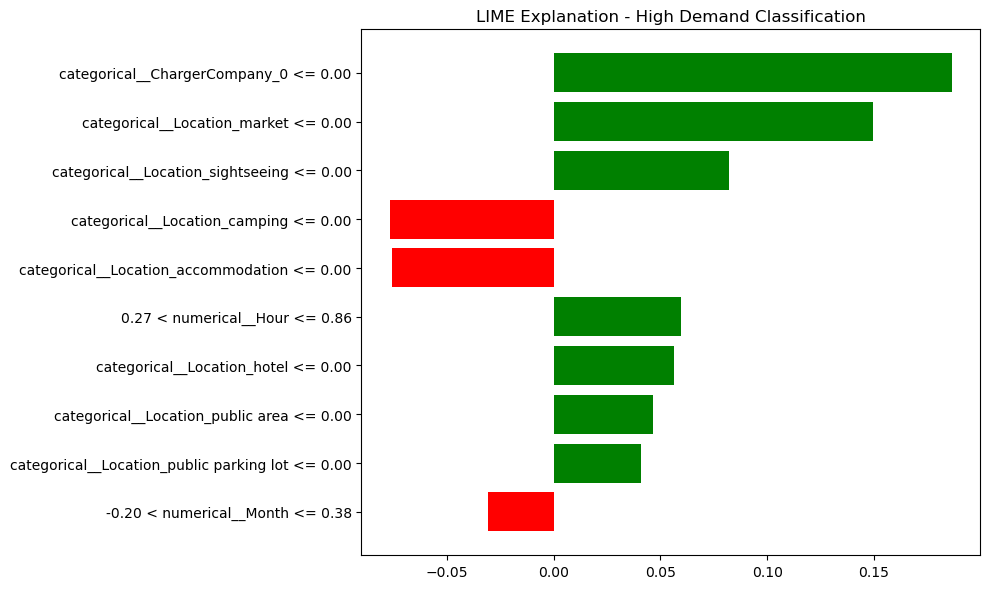

In [65]:
# Display the LIME explanation

fig = lime_explanation.as_pyplot_figure(
    label=1
)

fig.set_size_inches(10, 6)

plt.title(
    "LIME Explanation - High Demand Classification"
)

plt.tight_layout()

plt.show()

In [66]:
# Save your explainability results


# Create explainability folder

os.makedirs("explainability", exist_ok=True)

# Save feature importance
feature_importance_df.to_csv(
    "explainability/feature_importance.csv",
    index=False
)

# Save SHAP values
np.save(
    "explainability/shap_values.npy",
    shap_values.values
)

# Save LIME explanation
lime_results = pd.DataFrame(
    lime_explanation.as_list(label=1),
    columns=["Feature", "Contribution"]
)

lime_results.to_csv(
    "explainability/lime_explanation.csv",
    index=False
)

print("All explainability results saved successfully!")


All explainability results saved successfully!


In [67]:
# saving the SHAP charts as images


shap.plots.bar(
    shap_values,
    show=False
)

plt.savefig(
    "explainability/shap_feature_importance.png",
    bbox_inches="tight"
)

plt.close()